# Lab 5: Data Preparation
### Reading Data, Distributions, Missing Values, Outliers, and Web Scraping

This Lab covers five core steps in preparing a dataset for analysis: loading data, identifying its distribution, handling missing values, detecting outliers, and collecting data from the web. Each section explains the concept, why it occurs, how to detect it, and how to work with it in code.

---
# Part 1: Reading Data

Before any analysis, data must be loaded into Python. The pandas library reads almost every common file format into a single structure called a DataFrame, a table similar to a spreadsheet.

In [1]:
import pandas as pd
import numpy as np

# Sample dataset saved in three formats for practice
np.random.seed(42)
df = pd.DataFrame({
    'EmployeeID': range(1, 201),
    'Age': np.random.randint(21, 60, 200),
    'Salary': np.random.normal(55000, 18000, 200).round(0),
    'YearsExperience': np.random.exponential(4, 200).round(1)
})

df.to_csv('employees.csv', index=False)
df.to_excel('employees.xlsx', index=False, sheet_name='Employees')
df.to_json('employees.json')
df.head()

,EmployeeID,Age,Salary,YearsExperience
0,1,59,85719.0,0.5
1,2,49,70725.0,0.6
2,3,35,55165.0,5.7
3,4,28,48420.0,3.9
4,5,41,66684.0,0.4


### 1.1 Reading Different File Formats

| File type | Function |
|---|---|
| CSV | `pd.read_csv('file.csv')` |
| Excel | `pd.read_excel('file.xlsx', sheet_name='Sheet1')` |
| JSON | `pd.read_json('file.json')` |

Regardless of the source format, the result is always a DataFrame, so the rest of the workflow does not depend on where the data came from.

In [2]:
df_csv  = pd.read_csv('employees.csv')
df_xlsx = pd.read_excel('employees.xlsx', sheet_name='Employees')
df_json = pd.read_json('employees.json')

print("CSV shape:", df_csv.shape, "| Excel shape:", df_xlsx.shape, "| JSON shape:", df_json.shape)
df_csv.head()

CSV shape: (200, 4) | Excel shape: (200, 4) | JSON shape: (200, 4)


,EmployeeID,Age,Salary,YearsExperience
0,1,59,85719.0,0.5
1,2,49,70725.0,0.6
2,3,35,55165.0,5.7
3,4,28,48420.0,3.9
4,5,41,66684.0,0.4


**Note:** To read from Google Drive in Colab, mount it first with `from google.colab import drive; drive.mount('/content/drive')`, then use the path `/content/drive/MyDrive/...`. A file can also be read directly from a URL, for example `pd.read_csv('https://example.com/data.csv')`.

### 1.2 First Look at the Data

Three commands to run on any new dataset:

In [3]:
df.info()      # column names, data types, count of non-missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   EmployeeID       200 non-null    int64  
 1   Age              200 non-null    int64  
 2   Salary           200 non-null    float64
 3   YearsExperience  200 non-null    float64
dtypes: float64(2), int64(2)
memory usage: 6.4 KB


In [4]:
df.describe()   # count, mean, std, min, quartiles, max for numeric columns

,EmployeeID,Age,Salary,YearsExperience
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,40.045000,58032.630000,4.390500
std,57.879185,11.826339,17775.020087,4.830042
min,1.000000,21.000000,17380.000000,0.000000
25%,50.750000,29.000000,45721.000000,0.900000
50%,100.500000,41.500000,57292.000000,2.750000
75%,150.250000,50.000000,71020.500000,5.925000
max,200.000000,59.000000,104220.000000,32.700000


---
### 1.3 Skewness and Kurtosis

After loading the data, the next question is what shape each column has. Two statistics describe this.

**Skewness** measures asymmetry: whether one tail of the distribution is longer than the other.

$$\text{Skewness} = \frac{\sum (x_i - \bar{x})^3 / n}{s^3}$$

| Value | Meaning | Example |
|---|---|---|
| Approximately 0 | Symmetric | A normal bell curve |
| Greater than 0 | Right-skewed, long tail on the right | Salary, house prices |
| Less than 0 | Left-skewed, long tail on the left | Age at retirement |

**Kurtosis** measures how heavy the tails are, or how peaked the distribution is compared to a normal curve.

$$\text{Kurtosis} = \frac{\sum (x_i - \bar{x})^4 / n}{s^4} - 3$$

| Value | Meaning |
|---|---|
| Approximately 0 | Tails similar to a normal distribution |
| Greater than 0 | Heavier tails, more extreme values, sharper peak |
| Less than 0 | Lighter tails, fewer extreme values, flatter top |

The values below can be verified against the plots that follow.

In [5]:
for col in ['Age', 'Salary', 'YearsExperience']:
    print(f"{col:18s} skew = {df[col].skew():6.2f}   kurtosis = {df[col].kurt():6.2f}")

Age                skew =  -0.04   kurtosis =  -1.27
Salary             skew =   0.03   kurtosis =  -0.45
YearsExperience    skew =   2.17   kurtosis =   6.77


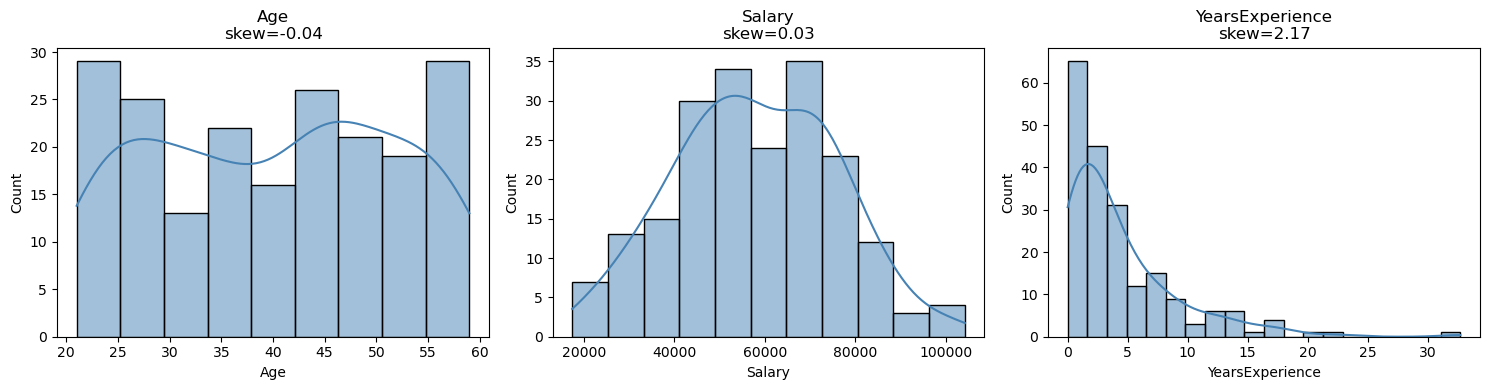

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Age', 'Salary', 'YearsExperience']):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(f"{col}\nskew={df[col].skew():.2f}")
plt.tight_layout()
plt.show()

**Interpreting the plots:**
- **Age** is roughly flat across the range, so its skew is close to 0.
- **Salary** is close to symmetric, forming a bell shape, so its skew is also close to 0.
- **YearsExperience** has a tall bar on the left and a long tail extending right. This is a right-skewed (positively skewed) distribution.

A log transform corrects a long right tail and is commonly applied before feeding skewed data into models that assume normally distributed inputs.

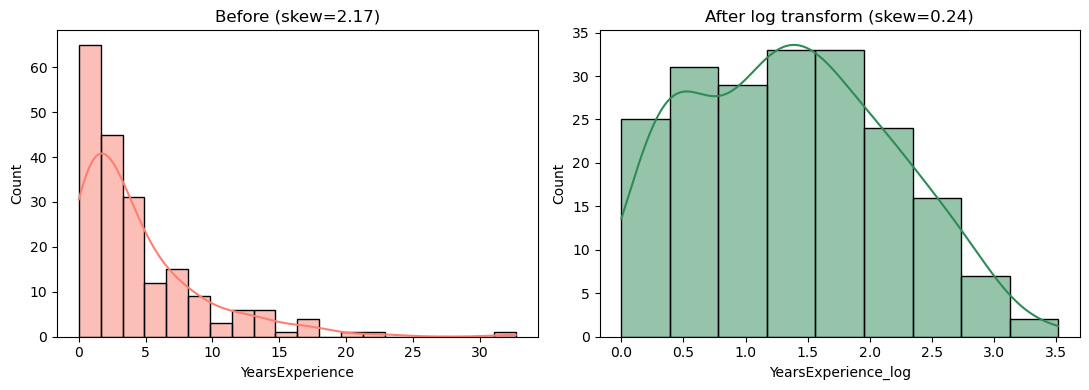

In [7]:
df['YearsExperience_log'] = np.log1p(df['YearsExperience'])  # log1p = log(1+x), handles zeros safely

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['YearsExperience'], kde=True, ax=axes[0], color='salmon')
axes[0].set_title(f"Before (skew={df['YearsExperience'].skew():.2f})")
sns.histplot(df['YearsExperience_log'], kde=True, ax=axes[1], color='seagreen')
axes[1].set_title(f"After log transform (skew={df['YearsExperience_log'].skew():.2f})")
plt.tight_layout()
plt.show()

---
# Part 2: Probability Distributions

### 2.1 What Is a Distribution

A distribution describes how the values of a variable are spread out: which values occur frequently, which occur rarely, and what shape this pattern forms when plotted.

For example, rolling a die 1000 times and plotting how often each number appears produces a shape. That shape is the distribution. Knowing it tells us what a typical value looks like, what counts as unusual, and which statistical methods are valid to apply.

### 2.2 Detecting a Distribution

| Method | Approach |
|---|---|
| Histogram or KDE plot | Plot the data and examine the shape directly |
| Skewness and kurtosis | Check symmetry and tail weight, as covered in Part 1 |
| Q-Q plot | Compares the data to a theoretical normal distribution; a straight line indicates normality |
| Statistical test | For example, the Shapiro-Wilk test formally checks for normality |

In practice, plotting a histogram is usually the fastest way to identify the shape of a variable.

The six distributions below are the most commonly encountered in exploratory data analysis. Each entry includes its formula, meaning, a real-world example, and a plot.

In [8]:
from scipy import stats
np.random.seed(42)
sns.set_style('whitegrid')

### 2.3.1 Normal (Gaussian) Distribution

- **Type:** Continuous
- **Formula (PDF):** $f(x) = \dfrac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}}$
- **Parameters:** mean $\mu$, standard deviation $\sigma$
- **Meaning:** symmetric bell shape, with most values clustered near the mean.
- **How to detect it:** skew close to 0, kurtosis close to 0, bell-shaped histogram.
- **Example:** heights, exam scores, measurement error.

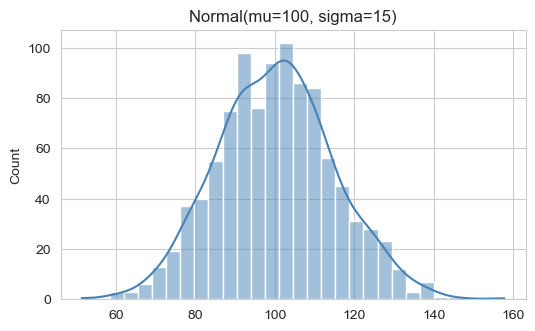

Skew (should be close to 0): 0.12


In [9]:
mu, sigma = 100, 15
normal_samples = stats.norm.rvs(mu, sigma, size=1000)

plt.figure(figsize=(6, 3.5))
sns.histplot(normal_samples, kde=True, color='steelblue', bins=30)
plt.title(f'Normal(mu={mu}, sigma={sigma})')
plt.show()
print('Skew (should be close to 0):', round(stats.skew(normal_samples), 2))

### 2.3.2 Uniform Distribution

- **Type:** Continuous (also exists in discrete form)
- **Formula (PDF):** $f(x) = \dfrac{1}{b-a}$ for $a \le x \le b$, otherwise $0$
- **Parameters:** lower bound $a$, upper bound $b$
- **Meaning:** every value in the range is equally likely, producing a flat histogram.
- **How to detect it:** histogram appears as a flat rectangle.
- **Example:** a random number generator, dice rolls, arrival time within a fixed window.

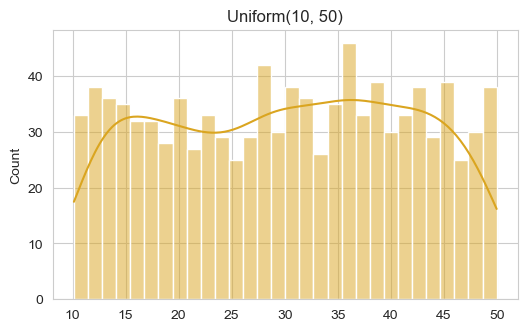

In [10]:
a, b = 10, 50
uniform_samples = stats.uniform.rvs(loc=a, scale=b - a, size=1000)

plt.figure(figsize=(6, 3.5))
sns.histplot(uniform_samples, kde=True, color='goldenrod', bins=30)
plt.title(f'Uniform({a}, {b})')
plt.show()

### 2.3.3 Binomial Distribution

- **Type:** Discrete
- **Formula (PMF):** $P(X=k) = \binom{n}{k} p^k (1-p)^{n-k}$
- **Parameters:** number of trials $n$, success probability $p$
- **Meaning:** counts how many successes occur across $n$ independent yes/no trials.
- **How to detect it:** discrete bar chart bounded between 0 and $n$.
- **Example:** number of heads in 20 coin flips, number of customers who buy out of 100 visitors.

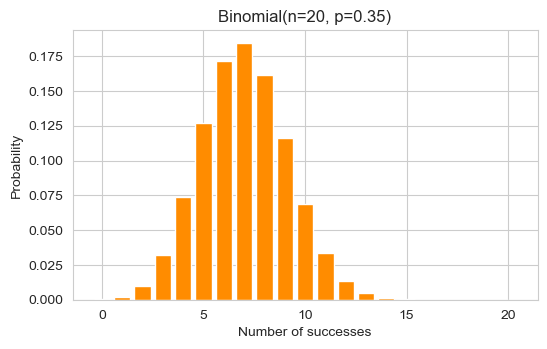

In [37]:
n, p = 20, 0.35
x = np.arange(0, n + 1)
pmf = stats.binom.pmf(x, n, p)

plt.figure(figsize=(6, 3.5))
plt.bar(x, pmf, color='darkorange')
plt.title(f'Binomial(n={n}, p={p})')
plt.xlabel('Number of successes')
plt.ylabel('Probability')
plt.show()

### 2.3.4 Poisson Distribution

- **Type:** Discrete
- **Formula (PMF):** $P(X=k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$
- **Parameter:** average rate $\lambda$ (events per interval)
- **Meaning:** describes how many times an event occurs in a fixed interval, given an average rate.
- **How to detect it:** discrete counts, right-skewed for small $\lambda$.
- **Example:** number of support tickets per hour, number of typos per page.

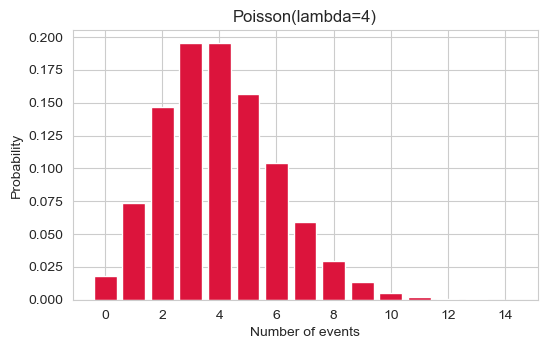

In [12]:
lam = 4
x = np.arange(0, 15)
pmf = stats.poisson.pmf(x, lam)

plt.figure(figsize=(6, 3.5))
plt.bar(x, pmf, color='crimson')
plt.title(f'Poisson(lambda={lam})')
plt.xlabel('Number of events')
plt.ylabel('Probability')
plt.show()

### 2.3.5 Exponential Distribution

- **Type:** Continuous
- **Formula (PDF):** $f(x) = \lambda e^{-\lambda x}$, $x \ge 0$
- **Parameter:** rate $\lambda$
- **Meaning:** the waiting time until the next event in a Poisson process. Always positive and right-skewed.
- **How to detect it:** tall bar near zero, long right tail, all values positive.
- **Example:** time until the next customer arrives, time until a machine part fails.

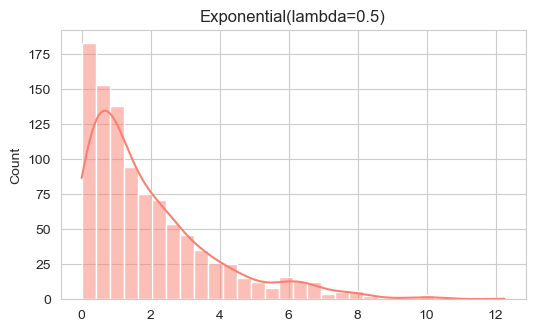

In [13]:
scale = 1 / 0.5   # scale = 1/lambda
exponential_samples = stats.expon.rvs(scale=scale, size=1000)

plt.figure(figsize=(6, 3.5))
sns.histplot(exponential_samples, kde=True, color='salmon', bins=30)
plt.title('Exponential(lambda=0.5)')
plt.show()

### 2.3.6 Log-Normal Distribution

- **Type:** Continuous
- **Formula:** $X$ is log-normal if $\ln(X)$ is normally distributed, i.e. $f(x) = \dfrac{1}{x\sigma\sqrt{2\pi}} e^{-\frac{(\ln x - \mu)^2}{2\sigma^2}}$
- **Parameters:** $\mu, \sigma$ of the underlying log values
- **Meaning:** always positive with a long right tail. Common for monetary and count-based data.
- **How to detect it:** right-skewed in raw form, but applying a log transform makes it approximately normal.
- **Example:** income, house prices, stock prices, city population.

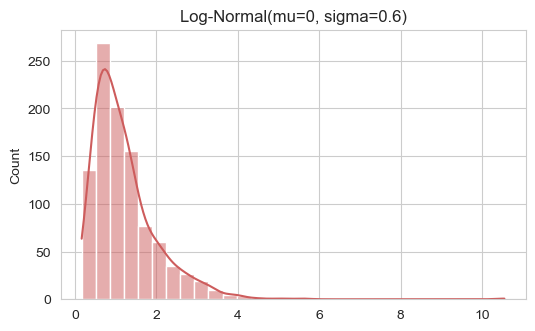

Skew (right-skewed): 2.68


In [14]:
mu_log, sigma_log = 0, 0.6
lognormal_samples = stats.lognorm.rvs(s=sigma_log, scale=np.exp(mu_log), size=1000)

plt.figure(figsize=(6, 3.5))
sns.histplot(lognormal_samples, kde=True, color='indianred', bins=30)
plt.title(f'Log-Normal(mu={mu_log}, sigma={sigma_log})')
plt.show()
print('Skew (right-skewed):', round(stats.skew(lognormal_samples), 2))

### 2.4 Summary Table

| Distribution | Type | Detect by | Example |
|---|---|---|---|
| Normal | Continuous | Symmetric bell, skew near 0 | Heights, test scores |
| Uniform | Continuous | Flat rectangle | Dice rolls, random number generator |
| Binomial | Discrete | Bar chart bounded between 0 and n | Coin flips, conversion counts |
| Poisson | Discrete | Discrete counts, right-skewed for small rate | Support tickets per hour |
| Exponential | Continuous | Tall near zero, long right tail | Wait time until next event |
| Log-Normal | Continuous | Right-skewed, becomes normal after log transform | Income, house prices |

---
# Part 3: Missing Value Management

### 3.1 What Is a Missing Value

A missing value is a cell in a dataset with no recorded entry, represented as `NaN` (Not a Number) in pandas. Most real-world datasets contain some missing values.

### 3.2 How Missing Values Occur

| Cause | Example |
|---|---|
| Not collected | A survey question was skipped |
| Not applicable | Spouse name for an unmarried person |
| Lost in transfer | A system error during data entry |
| Measurement failure | A sensor failed to record a reading |

The goal is not to remove every missing value automatically, but to understand why the data is missing and choose a treatment that does not distort the analysis.

In [15]:
np.random.seed(42)
mdf = pd.DataFrame({
    'Age': np.random.randint(20, 60, 300).astype(float),
    'Salary': np.random.normal(52000, 15000, 300),
    'Rating': np.random.uniform(1, 5, 300),
    'Department': np.random.choice(['IT', 'HR', 'Sales', 'Finance'], 300),
    'JoinDate': pd.date_range('2018-01-01', periods=300, freq='7D')
})
# Randomly remove some values to have data to work with
for col, frac in [('Age', 0.05), ('Salary', 0.15), ('Rating', 0.08), ('Department', 0.03)]:
    idx = mdf.sample(frac=frac, random_state=1).index
    mdf.loc[idx, col] = np.nan

mdf.head()

,Age,Salary,Rating,Department,JoinDate
0,58.0,59098.564369,1.080285,HR,2018-01-01
1,48.0,50907.566310,2.288317,HR,2018-01-08
2,34.0,39298.094229,1.845792,IT,2018-01-15
3,27.0,29277.291630,2.309989,IT,2018-01-22
4,40.0,NaN,1.479049,IT,2018-01-29


### 3.3 Detecting Missing Values

In [16]:
missing_count = mdf.isnull().sum()
missing_pct = (mdf.isnull().mean() * 100).round(1)
missing_summary = pd.DataFrame({'missing_count': missing_count, 'missing_pct': missing_pct})
missing_summary.sort_values('missing_pct', ascending=False)

,missing_count,missing_pct
Salary,45,15.0
Rating,24,8.0
Age,15,5.0
Department,9,3.0
JoinDate,0,0.0


A summary table gives the totals, but a heatmap reveals patterns, such as two columns missing together, more quickly.

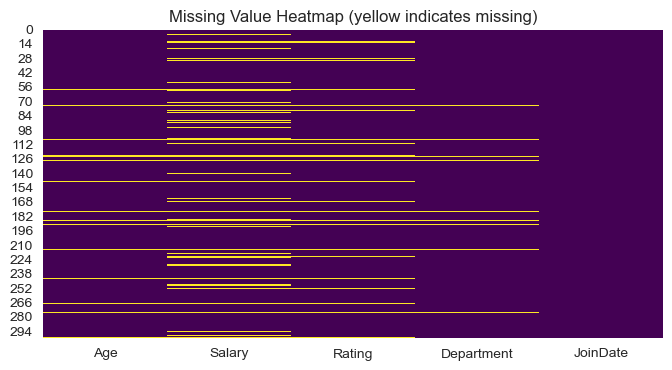

In [17]:
plt.figure(figsize=(8, 4))
sns.heatmap(mdf.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Value Heatmap (yellow indicates missing)')
plt.show()

### 3.4 Handling Missing Values

**Option A: Deletion.** Suitable only when the missing fraction is small; otherwise usable data is lost.

In [18]:
# Drop columns more than 30% missing
cols_to_drop = missing_summary[missing_summary['missing_pct'] > 30].index
mdf_clean = mdf.drop(columns=cols_to_drop)

# Drop rows missing more than one value
mdf_clean = mdf_clean.dropna(thresh=len(mdf_clean.columns) - 1)
print("Rows before:", len(mdf), "| Rows after dropping sparse rows:", len(mdf_clean))

Rows before: 300 | Rows after dropping sparse rows: 276


**Option B: Imputation.** Fill in a reasonable value instead of removing data.

| Situation | Typical choice |
|---|---|
| Numeric, roughly symmetric | Mean |
| Numeric, skewed or has outliers | Median |
| Categorical | Mode (most frequent value) |
| Time-ordered data | Forward-fill or backward-fill |
| Correlated numeric columns | KNN imputation, using similar rows |

In [19]:
mdf_imp = mdf.copy()

mdf_imp['Age'] = mdf_imp['Age'].fillna(mdf_imp['Age'].mean())          # symmetric: mean
mdf_imp['Salary'] = mdf_imp['Salary'].fillna(mdf_imp['Salary'].median())  # skewed: median
mdf_imp['Department'] = mdf_imp['Department'].fillna(mdf_imp['Department'].mode()[0])  # categorical: mode

mdf_imp[['Age', 'Salary', 'Department']].isnull().sum()

Age           0
Salary        0
Department    0
dtype: int64

In [20]:
# Time-ordered data: forward-fill and backward-fill
ts = mdf.set_index('JoinDate').sort_index()
ts_ffill = ts['Rating'].ffill()   # carries the last known value forward
ts_bfill = ts['Rating'].bfill()   # carries the next known value backward

In [21]:
from sklearn.impute import KNNImputer

numeric_cols = ['Age', 'Salary', 'Rating']
imputer = KNNImputer(n_neighbors=5)
mdf_knn = mdf.copy()
mdf_knn[numeric_cols] = imputer.fit_transform(mdf_knn[numeric_cols])
mdf_knn[numeric_cols].isnull().sum()

Age       0
Salary    0
Rating    0
dtype: int64

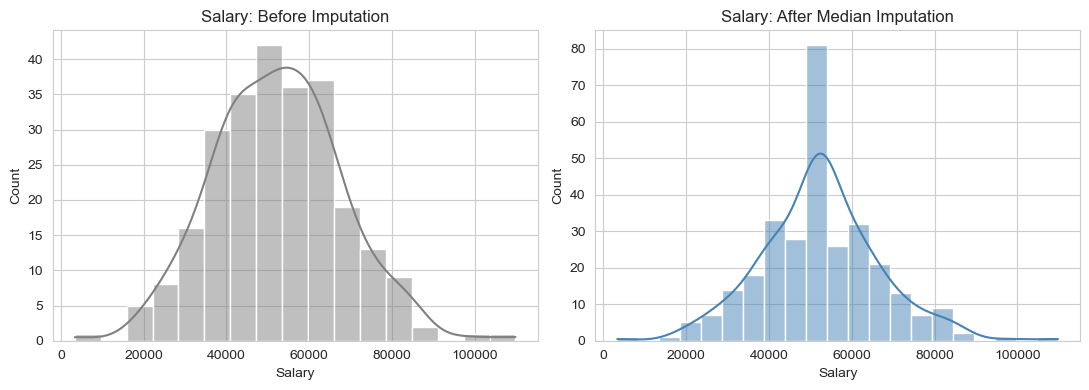

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(mdf['Salary'].dropna(), kde=True, ax=axes[0], color='gray')
axes[0].set_title('Salary: Before Imputation')
sns.histplot(mdf_imp['Salary'], kde=True, ax=axes[1], color='steelblue')
axes[1].set_title('Salary: After Median Imputation')
plt.tight_layout()
plt.show()

**Note:** If the imputed distribution shows an unnatural spike at the mean or median, imputation has compressed the natural spread of the data. This is worth noting in an analysis, particularly when the missing fraction was large.

---
# Part 4: Outlier Detection and Treatment

### 4.1 What Is an Outlier

An outlier is a data point that differs substantially from the rest of the dataset. It may be a genuine extreme value, such as a very high income in a salary dataset, or a data-entry error, such as an age recorded as 200.

Detection identifies where outliers are located. Judgment determines what to do with them.

### 4.2 Detecting Outliers

In [23]:
np.random.seed(42)
odf = pd.DataFrame({
    'Income': np.concatenate([np.random.normal(50000, 8000, 190),
                               np.random.uniform(150000, 300000, 10)]),
    'Age': np.concatenate([np.random.randint(22, 55, 195), np.array([120, -5, 130, 200, 110])]),
    'PurchaseAmount': np.random.exponential(200, 200)
})
odf.head()

,Income,Age,PurchaseAmount
0,53973.713224,23,25.298199
1,48893.885591,48,25.005246
2,55181.508305,23,209.513677
3,62184.238851,47,274.119544
4,48126.773002,38,175.110755


**Method A: IQR (Interquartile Range) rule.** Flags anything outside `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`. Based on quartiles rather than the mean, making it robust for skewed data.

In [24]:
Q1 = odf['Income'].quantile(0.25)
Q3 = odf['Income'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

iqr_outliers = odf[(odf['Income'] < lower) | (odf['Income'] > upper)]
print(f'IQR bounds: [{lower:.0f}, {upper:.0f}]  |  Outliers found: {len(iqr_outliers)}')
iqr_outliers.head()

IQR bounds: [28297, 72239]  |  Outliers found: 10


,Income,Age,PurchaseAmount
190,277670.500728,40,138.007284
191,197538.300773,24,18.186419
192,175423.912003,34,154.051673
193,233520.189369,49,176.784612
194,290423.216124,41,273.643330


**Method B: Z-score rule.** Flags anything more than `k` standard deviations from the mean, commonly `k=3`. Assumes roughly normal data; use the IQR method instead for heavily skewed data.

In [25]:
from scipy import stats

z_scores = np.abs(stats.zscore(odf['Age']))
z_outliers = odf[z_scores > 3]
print('Z-score outliers found:', len(z_outliers))
z_outliers

Z-score outliers found: 4


,Income,Age,PurchaseAmount
195,254404.469501,120,113.006930
197,164576.474066,130,66.752436
198,242251.084005,200,90.222965
199,298508.077516,110,207.644922


**Visualizing outliers**

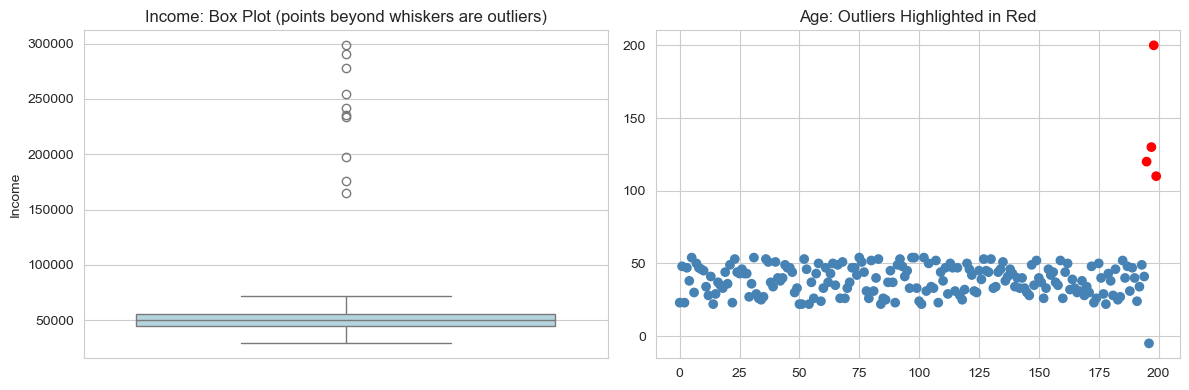

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=odf['Income'], ax=axes[0], color='lightblue')
axes[0].set_title('Income: Box Plot (points beyond whiskers are outliers)')

colors_ = np.where(z_scores > 3, 'red', 'steelblue')
axes[1].scatter(odf.index, odf['Age'], c=colors_)
axes[1].set_title('Age: Outliers Highlighted in Red')
plt.tight_layout()
plt.show()

### 4.3 Treating Outliers

| Method | What it does | When to use |
|---|---|---|
| Capping (winsorizing) | Clips extreme values to a set minimum or maximum | Default choice; preserves all rows |
| Removal | Deletes the affected rows | Only when the values are confirmed errors |
| Transformation | For example, a log transform compresses the scale | When values are genuine but extreme |

In [27]:
# Capping
lower_cap = odf['Income'].quantile(0.05)
upper_cap = odf['Income'].quantile(0.95)
odf['Income_capped'] = odf['Income'].clip(lower=lower_cap, upper=upper_cap)
odf[['Income', 'Income_capped']].describe()

,Income,Income_capped
count,200.000000,200.000000
mean,59098.085548,51219.328217
std,42712.760333,9123.482898
min,29042.039167,38157.293983
25%,44775.437472,44775.437472
50%,50544.364718,50544.364718
75%,55760.936125,55760.936125
max,298508.077516,76402.109369


In [28]:
# Removal
odf_no_outliers = odf[z_scores <= 3]
print(f'Rows before: {len(odf)}  |  Rows after removing Age outliers: {len(odf_no_outliers)}')

Rows before: 200  |  Rows after removing Age outliers: 196


In [29]:
# Transformation
odf['PurchaseAmount_log'] = np.log1p(odf['PurchaseAmount'])
print('Skew before:', round(odf['PurchaseAmount'].skew(), 2))
print('Skew after :', round(odf['PurchaseAmount_log'].skew(), 2))

Skew before: 2.39
Skew after : -0.56


There is no universally correct treatment. Capping preserves sample size but alters the extreme values, removal is clean but reduces the dataset, and transformation is gentle but changes the scale of the variable. The choice depends on why the outlier exists and how the data will be used.

---
# Part 5: Web Scraping

### 5.1 What Is Web Scraping

Web scraping is the process of automatically extracting data from a web page rather than from a file. Instead of reading a CSV or Excel file, the data source is a live website's HTML. Python fetches the page, parses its structure, and extracts the required content into a DataFrame.

### 5.2 Ways to Scrape Data

| Method | Approach | Best suited for |
|---|---|---|
| `requests` with `BeautifulSoup` | Fetch raw HTML, then parse specific tags or classes | Most static websites |
| `pandas.read_html()` | Extracts `<table>` elements directly into DataFrames | Pages with clean HTML tables |
| Official API | The site provides structured JSON data directly | Preferred whenever available; more stable and explicitly permitted |
| Selenium or Playwright | Controls a real browser | Pages that load content dynamically with JavaScript |

The first two methods cover most common use cases and are demonstrated below.

**Before scraping any site**, check its `robots.txt` file, for example `https://example.com/robots.txt`, and its terms of service. Respect rate limits, and prefer an official API when one exists.

### 5.3 Step 1: Fetching the Page

In [30]:
import requests
from bs4 import BeautifulSoup

headers = {'User-Agent': 'Mozilla/5.0 (EDA-Lab-Guide)'}   # some servers reject requests with no User-Agent
url = 'https://example.com'

response = requests.get(url, headers=headers, timeout=10)
print('Status code:', response.status_code)   # 200 indicates success

Status code: 200


### 5.4 Step 2: Parsing the HTML

In [31]:
soup = BeautifulSoup(response.text, 'html.parser')

print('Page title:', soup.title.string if soup.title else None)

# Extract all headings
headings = [h.get_text(strip=True) for h in soup.find_all(['h1', 'h2'])]
print('Headings:', headings[:10])

Page title: Example Domain
Headings: []


Targeted extraction narrows the search to a specific tag or class, so only the required elements are pulled:

In [32]:
# By tag and class name
items = soup.find_all('div', class_='some-class-name')
texts = [item.get_text(strip=True) for item in items]

# By CSS selector, which is more flexible
links = [a['href'] for a in soup.select('a.some-link-class')]

### 5.5 Step 3: Extracting HTML Tables Directly

When the required data is already inside a `<table>` element, pandas can extract it without manual parsing.

In [33]:
tables = pd.read_html(response.text)   # returns a list of DataFrames, one per table
print(f'Found {len(tables)} table(s) on the page')
tables[0].head() if tables else "No tables found on this page"


/var/folders/hd/84sk8w4d1g18gpznhj01rzgh0000gn/T/ipykernel_57902/3781503993.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)   # returns a list of DataFrames, one per table


ImportError: Missing optional dependency 'html5lib'.  Use pip or conda to install html5lib.

### 5.6 Handling Multiple Pages

Most listing sites split results across several pages. Looping through page numbers with a short delay between requests avoids overloading the server.

In [ ]:
import time

all_rows = []
for page_num in range(1, 4):   # pages 1 to 3
    page_url = f'{url}?page={page_num}'
    try:
        r = requests.get(page_url, headers=headers, timeout=10)
        r.raise_for_status()
        page_soup = BeautifulSoup(r.text, 'html.parser')
        # extract the elements representing one row on this page, for example:
        # rows = page_soup.find_all('div', class_='listing')
        # all_rows.extend(rows)
        time.sleep(1)  # delay between requests
    except requests.RequestException as e:
        print(f'Page {page_num} failed: {e}')

print('Collected', len(all_rows), 'rows across pages')

---
## Summary

| Part | Topic |
|---|---|
| 1. Reading Data | Loading data and identifying its shape |
| 2. Distributions | Recognizing which pattern a variable follows |
| 3. Missing Values | Identifying and filling gaps in the data |
| 4. Outliers | Identifying unusual points and deciding how to treat them |
| 5. Web Scraping | Extracting data from a website into a DataFrame |